# What would it take? Planning the next molecules

`KAN_Transfer_Ledger` is a gate: it says, per component of a reaction, whether anything a model
learned about that component holds for a molecule it has not seen. On most of the tables in this
series the answer was no. This notebook asks the next question: **what would change that?** More
molecules, or a better description of a molecule?

Three tools from `transferledger` (a package in this repository, `packages/transferledger`), and
a check of each against data it has not seen:

1. **A learning curve in molecules** (`learning_curve`). Train on 4, 6, 9, ... of the molecules in
   hand, score on molecules held out, and see how the skill on a new molecule grows.
2. **Forecast first, then reveal** (`backtest`). On the tables with molecules to spare, measure
   the curve on a part of them, then really add molecules and measure again. This decides what
   a curve may be allowed to say about more molecules.
3. **The detection floor** (`detectable`). Add to the table a made-up property that captures a
   known share of what distinguishes one molecule from another, run the whole analysis, and
   count how often it is found. That says what the molecules in hand *could* have shown, and
   how many molecules a weaker property would need.

Skill is the share of the baseline's loss removed on held-out rows (0 is predicting the training
mean). Every interval is over held-out molecules. All data are downloaded at run time.

In [1]:
import os
import time
import warnings

warnings.filterwarnings("ignore")

import importlib.metadata as md
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from joblib import Parallel, delayed
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor

from pycse.sklearn._plotstyle import BASELINE, MUTED, PX, SERIES, finish_axes, style_axes
from pycse.sklearn.kan_interpret import prune_collinear
from transferledger import (
    NewGroups,
    PieceModel,
    backtest,
    detectable,
    learning_curve,
    unit_ceiling,
)

versions = {p: md.version(p) for p in ["transferledger", "pycse", "numpy", "scikit-learn", "scipy"]}
print("Versions: " + ", ".join(f"{k} {v}" for k, v in versions.items()))
N_JOBS = min(4, os.cpu_count() or 1)
# PLAN_FAST=1 runs every experiment with a handful of trials (a smoke test of the notebook);
# PLAN_OUT=<folder> also writes every table as JSON
FAST = bool(os.environ.get("PLAN_FAST"))
PLAN_OUT = os.environ.get("PLAN_OUT")
pd.set_option("display.width", 250, "display.max_columns", 40, "display.max_colwidth", 120)

Versions: transferledger 0.2.0, pycse 2.13.0, numpy 2.5.4, scikit-learn 1.9.1, scipy 1.18.1


## Helpers

In [2]:
TABLES, CEILINGS, CURVES, BACKTESTS, FLOORS, SAVED = {}, {}, {}, {}, {}, {}


def floor_text(D, shape):
    # the smallest share of the unit-to-unit variance a planted property needed to be found
    f = D.floor(shape)
    if f is None:
        return "none planted was enough"
    return f"{f:.0%} or less" if f <= D.power["share"].min() else f"{f:.0%}"


def add_table(name, X_df, y, family, units, hypothesis=()):
    # prune near-duplicate descriptors as the dataset notebooks do, and remember the units
    names = list(X_df.columns)
    kept, dropped = prune_collinear(
        X_df.to_numpy(dtype=float), names, 0.85, keep_first=list(hypothesis)
    )
    X = X_df[kept].reset_index(drop=True)
    TABLES[name] = {"X": X, "y": np.asarray(y, dtype=float), "family": family,
                    "units": {k: np.asarray(v) for k, v in units.items()}}  # fmt: skip
    counts = ", ".join(f"{len(np.unique(v))} {k}s" for k, v in units.items())
    print(f"{name}: {len(X)} rows, {len(kept)} variables after pruning {len(dropped)}; {counts}")


def boosting(family):
    return (GradientBoostingRegressor if family == "gaussian" else GradientBoostingClassifier)(
        n_estimators=300, learning_rate=0.1, max_depth=4, min_samples_split=5,
        min_samples_leaf=3, subsample=0.8, random_state=42,
    )  # fmt: skip


def plot_curves(items, ncols=3):
    # one panel per component: skill on a new unit against the number of units trained on
    nrows = int(np.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 3.5 * nrows), squeeze=False)
    colors = [SERIES[0], SERIES[1], MUTED]
    for ax, (title, L) in zip(axes.ravel(), items):
        style_axes(ax)
        for k, rung in enumerate(L.rungs):
            c = L.curve[L.curve.rung == rung].sort_values("units")
            x = c.units.to_numpy(float) * (1 + 0.03 * (k - 1))
            ax.vlines(x, c.lo.clip(lower=-1), c.hi, color=colors[k], linewidth=1.2)
            ax.plot(x, c.skill.clip(lower=-1), "o-", color=colors[k], markersize=3.5, linewidth=1.2,
                    label=rung.split(",")[0])  # fmt: skip
        ax.axhline(0.0, color=BASELINE, linewidth=PX, linestyle="--")
        ax.set_xscale("log")
        ticks = sorted(set(L.curve.units))
        ax.set_xticks(ticks)
        ax.set_xticklabels([str(t) for t in ticks])
        ax.minorticks_off()
        ax.set_ylim(-1.0, 1.0)
        finish_axes(
            ax, f"{title}: {L.state()}", f"{L.unit}s trained on", "skill on a new " + L.unit
        )
        if ax.get_legend() is not None:
            ax.get_legend().remove()
    for ax in axes.ravel()[len(items) :]:
        ax.axis("off")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=3,
        frameon=False,
        fontsize=9,
        bbox_to_anchor=(0.5, -0.02),
    )
    plt.tight_layout(rect=(0, 0.04, 1, 1))
    plt.show()


def save(name, obj):
    SAVED[name] = obj
    if PLAN_OUT:
        with open(os.path.join(PLAN_OUT, "planning.json"), "w", encoding="utf-8") as f:
            json.dump(SAVED, f, indent=1, default=float)

## 1. The tables

The four reaction tables are loaded as in their own notebooks. A unit is a molecule of one
component; only components with at least a dozen molecules get a learning curve (three bases or
four solvents leave nothing to train on once some are held out). The fifth table is not
chemistry: California house prices, with census blocks grouped into 160 regions, which gives
many units to spare for the checks.

In [3]:
from rdkit import Chem, RDLogger

RDLogger.DisableLog("rdApp.*")  # the kraken table has blank SMILES rows

BASE = "https://raw.githubusercontent.com/doyle-lab-ucla/ochem-data/main/"
rxn = pd.read_csv(BASE + "Vbur/rxns/smiles.csv")
kraken = pd.read_csv(BASE + "kraken/kraken.csv")
SPHERE = 4.0 / 3.0 * np.pi * 3.5**3  # 179.6 cubic angstrom


def canon(s):
    m = Chem.MolFromSmiles(str(s))
    return Chem.MolToSmiles(m) if m is not None else None


kraken["key"] = kraken["ligand"].astype(str).str.lower().str.strip()
kraken["csmi"] = kraken["can_smiles"].where(kraken["can_smiles"].notna()).map(canon)
kraken = kraken.drop_duplicates("key")
rxn["key"] = rxn["ligand_name"].str.lower().str.strip()
rxn["csmi"] = rxn["ligand_smiles"].map(canon)

by_name = rxn.merge(kraken, on="key", how="left", suffixes=("", "_k"))
missing = by_name["id"].isna()
by_smi = rxn[missing].merge(
    kraken.drop_duplicates("csmi"), on="csmi", how="left", suffixes=("", "_k")
)
data = pd.concat([by_name[~missing], by_smi]).reset_index(drop=True)
print(
    f"{len(rxn)} reactions; matched by name {(~missing).sum()}, by SMILES {by_smi['id'].notna().sum()}, unmatched {data['id'].isna().sum()}"
)
data = data[data["id"].notna()].copy()

KRAKEN = {
    "pct_Vbur_min": ("vbur_vbur_min", 100.0 / SPHERE),
    "pct_Vbur_Boltz": ("vbur_vbur_boltz", 100.0 / SPHERE),
    "pct_Vbur_max": ("vbur_vbur_max", 100.0 / SPHERE),
    "Sterimol_B1": ("sterimol_B1_boltz", 1.0),
    "Sterimol_B5": ("sterimol_B5_boltz", 1.0),
    "Sterimol_L": ("sterimol_L_boltz", 1.0),
    "E_HOMO": ("fmo_e_homo_boltz", 1.0),
    "E_LUMO": ("fmo_e_lumo_boltz", 1.0),
    "V_min": ("vmin_vmin_boltz", 1.0),
    "NBO_charge_P": ("nbo_P_boltz", 1.0),
    "pyramidalization_P": ("pyr_P_boltz", 1.0),
    "dipole": ("dipolemoment_boltz", 1.0),
}
X_df = pd.DataFrame({k: data[c].astype(float) * s for k, (c, s) in KRAKEN.items()})

# the five substrate pairs, by SMILES
ELEC = {"ClC1=CC=C(C(F)(F)F)C=C1": "4-CF3-C6H4Cl", "ClC1=CC=C(OC)C=C1": "4-MeO-C6H4Cl"}
NUC = {
    "OB(O)C1=CC=C(C(F)(F)F)C=C1": "4-CF3-phenyl", "OB(O)C1=C(C)C=C(C)C=C1C": "mesityl",
    "OB(O)C1=CC=C(C(OCC)=O)C=C1": "4-CO2Et-phenyl", "OB(O)C1=CC=C(OC)C=C1": "4-MeO-phenyl",
    "OB(O)C1=CC=CC=C1": "phenyl",
}  # fmt: skip
data["reaction"] = (
    data.chloride_smiles.map(ELEC) + " + " + data.boronic_acid_smiles.map(NUC) + "B(OH)2"
)
assert data["reaction"].notna().all() and data["reaction"].nunique() == 5
REACTIONS = sorted(data["reaction"].unique())
for r in REACTIONS[1:]:  # the first pair is the reference level
    X_df["rxn: " + r] = (data["reaction"] == r).astype(float)
X_df.index = data.index

# Active, relative to the reaction. The five pairs differ in intrinsic reactivity: the best
# ligand reaches 91 % with one pair and 25 % with another, so one pooled yield cut would call
# most ligands active in the easy pair and almost none in the hard one. The paper shades an
# inactive band per reaction; here a ligand counts as active when it reaches a quarter of the
# best yield obtained with that same substrate pair.
best = data.groupby("reaction")["yield"].transform("max")
ACTIVE_FRACTION = 0.25
y = (data["yield"] >= ACTIVE_FRACTION * best).astype(int).to_numpy()
TASK = "classification"
Y_LABEL = "P(active)"
SUCCESS = y
SUCCESS_RULE = (
    f"yield at least {ACTIVE_FRACTION:.0%} of the best yield with the same substrate pair"
)
COMPONENT = {
    k: "ligand sterics"
    for k in [
        "pct_Vbur_min",
        "pct_Vbur_Boltz",
        "pct_Vbur_max",
        "Sterimol_B1",
        "Sterimol_B5",
        "Sterimol_L",
    ]
}
COMPONENT.update(
    {
        k: "ligand electronics"
        for k in ["E_HOMO", "E_LUMO", "V_min", "NBO_charge_P", "pyramidalization_P", "dipole"]
    }
)
COMPONENT.update({c: "substrate pair" for c in X_df.columns if c.startswith("rxn:")})
print(
    data.groupby("reaction")
    .agg(
        mean_yield=("yield", "mean"),
        best=("yield", "max"),
        n=("yield", "size"),
        active=("yield", lambda s: (s >= ACTIVE_FRACTION * s.max()).mean()),
    )
    .round(2)
)
_ = X_df.describe().T[["mean", "min", "max"]].round(2)
GROUPS = data["key"].to_numpy()
HYPOTHESIS = ["pct_Vbur_min"]

450 reactions; matched by name 450, by SMILES 0, unmatched 0
                                     mean_yield   best   n  active
reaction                                                          
4-CF3-C6H4Cl + 4-MeO-phenylB(OH)2         36.97   91.0  90    0.57
4-MeO-C6H4Cl + 4-CF3-phenylB(OH)2         20.14   90.0  90    0.33
4-MeO-C6H4Cl + 4-CO2Et-phenylB(OH)2        9.56  100.0  90    0.13
4-MeO-C6H4Cl + mesitylB(OH)2               9.73   63.0  90    0.24
4-MeO-C6H4Cl + phenylB(OH)2               15.16  100.0  90    0.23


In [4]:
add_table("Ligand cliff", X_df, y, "binomial", {"ligand": GROUPS}, HYPOTHESIS)

Ligand cliff: 450 rows, 15 variables after pruning 1; 90 ligands


In [5]:
URL = "https://raw.githubusercontent.com/b-shields/edbo/master/examples/DOE/data/aryl_amination/science_dft.csv"
RXN = "https://raw.githubusercontent.com/doylelab/rxnpredict/master/"
raw = pd.read_csv(URL)
CHOSEN = {
    "additive": [
        "additive_E_LUMO", "additive_E_HOMO", "additive_.C3_NMR_shift", "additive_.C4_NMR_shift",
        "additive_.C5_NMR_shift", "additive_.N1_electrostatic_charge", "additive_.O1_electrostatic_charge",
        "additive_dipole_moment", "additive_molecular_volume",
    ],
    "aryl halide": [
        "aryl_halide_E_LUMO", "aryl_halide_E_HOMO", "aryl_halide_.C1_NMR_shift",
        "aryl_halide_.C1_electrostatic_charge", "aryl_halide_.C4_NMR_shift", "aryl_halide_.H2_NMR_shift",
        "aryl_halide_dipole_moment", "aryl_halide_molecular_volume", "aryl_halide_hardness",
    ],
    "base": ["base_E_HOMO", "base_.N1_electrostatic_charge", "base_molecular_volume"],
    "ligand": ["ligand_.P1_electrostatic_charge", "ligand_dipole_moment", "ligand_.C1_NMR_shift"],
}  # fmt: skip
COMPONENT = {c: comp for comp, cols in CHOSEN.items() for c in cols}
X_df = raw[list(COMPONENT)].copy()
const = [c for c in X_df.columns if X_df[c].nunique() <= 1]
X_df = X_df.drop(columns=const)
print(f"Dropped constant descriptors: {const}")
y = raw["yield"].to_numpy(dtype=float)
TASK = "regression"
Y_LABEL = "yield (%)"
SUCCESS = (y > 20.0).astype(int)
SUCCESS_RULE = "yield above 20 %"

stats = X_df.agg(["mean", "std"]).T
print(f"Descriptor means are {stats['mean'].abs().max():.3f} or less and standard deviations "
      f"{stats['std'].min():.3f} to {stats['std'].max():.3f}: the table is standardized.")  # fmt: skip


def recover_names(key_col, table_col, table, names, checks):
    """Map each dataset level of key_col to a molecule name, then verify on other descriptors."""
    rank = np.argsort(np.argsort(table[table_col].to_numpy()))
    levels = np.sort(raw[key_col].unique())
    assert len(levels) == len(table), f"{len(levels)} levels vs {len(table)} molecules"
    mapping = {i: levels[rank[i]] for i in range(len(table))}
    for s_col, t_col in checks:
        lv, rk = np.sort(raw[s_col].unique()), np.argsort(np.argsort(table[t_col].to_numpy()))
        for i in range(len(table)):
            seen = raw.loc[raw[key_col] == mapping[i], s_col].unique()
            assert len(seen) == 1 and np.isclose(seen[0], lv[rk[i]]), (
                f"{t_col} disagrees for {names[i]}"
            )
    return {mapping[i]: names[i] for i in range(len(table))}


def name_list(stem):
    n = pd.read_csv(RXN + f"smiles/{stem}-list.csv")
    return n["name"].tolist()[: len(pd.read_csv(RXN + f"R/{stem}.csv"))]


tables = {s: pd.read_csv(RXN + f"R/{s}.csv") for s in ["aryl_halide", "additive", "base", "ligand"]}
raw["aryl_halide"] = raw["aryl_halide_.C1_NMR_shift"].map(
    recover_names("aryl_halide_.C1_NMR_shift", "aryl_halide_*C1_NMR_shift", tables["aryl_halide"], name_list("aryl_halide"),
                  [("aryl_halide_.C4_NMR_shift", "aryl_halide_*C4_NMR_shift"), ("aryl_halide_E_LUMO", "aryl_halide_E_LUMO"),
                   ("aryl_halide_molecular_volume", "aryl_halide_molecular_volume")])
)  # fmt: skip
raw["additive"] = raw["additive_.C3_NMR_shift"].map(
    recover_names("additive_.C3_NMR_shift", "additive_*C3_NMR_shift", tables["additive"], name_list("additive"),
                  [("additive_.C4_NMR_shift", "additive_*C4_NMR_shift"), ("additive_E_LUMO", "additive_E_LUMO")])
)  # fmt: skip
raw["base"] = raw["base_E_HOMO"].map(
    recover_names("base_E_HOMO", "base_E_HOMO", tables["base"], name_list("base"),
                  [("base_molecular_volume", "base_molecular_volume"), ("base_.N1_electrostatic_charge", "base_*N1_electrostatic_charge")])
)  # fmt: skip
raw["ligand"] = raw["ligand_dipole_moment"].map(
    recover_names("ligand_dipole_moment", "ligand_dipole_moment", tables["ligand"], name_list("ligand"),
                  [("ligand_.C1_NMR_shift", "ligand_*C1_NMR_shift"), ("ligand_.P1_electrostatic_charge", "ligand_*P1_electrostatic_charge")])
)  # fmt: skip
raw["halide"] = np.select(
    [raw.aryl_halide.str.contains("iodo"), raw.aryl_halide.str.contains("bromo")], ["I", "Br"], "Cl"
)

# The scaffold is the aryl halide without its halogen, keeping where the halogen was:
# 2- and 3-halopyridines are different substrates even though both lose a halogen to
# give pyridine. The names are written inconsistently ("1-ethyl-4-iodobenzene" but
# "1-bromo-4-ethylbenzene"), so the scaffold is read from the substituent named.


def scaffold_of(name):
    if "pyridine" in name:
        return f"pyridin-{name[0]}-yl"
    for key, label in [
        ("trifluoromethyl", "4-(trifluoromethyl)phenyl"),
        ("methoxy", "4-methoxyphenyl"),
        ("ethyl", "4-ethylphenyl"),
    ]:
        if key in name:
            return label
    raise ValueError(name)


raw["scaffold"] = raw.aryl_halide.map(scaffold_of)
assert raw["scaffold"].nunique() == 5
print("Names recovered and verified against two further descriptors each.")
print(f"{len(raw)} reactions: {raw.aryl_halide.nunique()} aryl halides, {raw.additive.nunique()} additives, "
      f"{raw.base.nunique()} bases ({', '.join(sorted(raw.base.unique()))}), {raw.ligand.nunique()} ligands "
      f"({', '.join(sorted(raw.ligand.unique()))}).")  # fmt: skip
GROUPS = raw["additive"].to_numpy()
HYPOTHESIS = []

Dropped constant descriptors: []
Descriptor means are 0.025 or less and standard deviations 0.994 to 1.005: the table is standardized.
Names recovered and verified against two further descriptors each.
3955 reactions: 15 aryl halides, 22 additives, 3 bases (BTMG, MTBD, P2Et), 4 ligands (AdBrettPhos, XPhos, t-BuBrettPhos, t-BuXPhos).


In [6]:
add_table(
    "Buchwald-Hartwig",
    X_df,
    y,
    "gaussian",
    {"aryl halide": raw["aryl_halide"].to_numpy(), "additive": raw["additive"].to_numpy()},
)

Buchwald-Hartwig: 3955 rows, 21 variables after pruning 3; 15 aryl halides, 22 additives


In [7]:
BASE = "https://raw.githubusercontent.com/b-shields/edbo/master/examples/DOE/data/direct_arylation/"
idx = pd.read_csv(BASE + "experiment_index.csv")
lig = pd.read_csv(BASE + "ligand-boltzmann_dft.csv")
bas = pd.read_csv(BASE + "base_dft.csv")
sol = pd.read_csv(BASE + "solvent_dft.csv")

LIG = {
    "ligand_pct_Vbur_P": "ligand_atom1_%VBur_Boltz", "ligand_E_HOMO": "ligand_homo_energy_Boltz",
    "ligand_E_LUMO": "ligand_lumo_energy_Boltz", "ligand_hardness": "ligand_hardness_Boltz",
    "ligand_dipole": "ligand_dipole_Boltz", "ligand_molar_volume": "ligand_molar_volume_Boltz",
}  # fmt: skip
BAS = {
    "base_dipole": "base_dipole",
    "base_molar_volume": "base_molar_volume",
    "base_E_HOMO": "base_homo_energy",
    "base_E_LUMO": "base_lumo_energy",
}
SOL = {
    "solvent_dipole": "solvent_dipole",
    "solvent_molar_volume": "solvent_molar_volume",
    "solvent_E_HOMO": "solvent_homo_energy",
    "solvent_E_LUMO": "solvent_lumo_energy",
}

df = idx.merge(
    lig[["ligand_SMILES", "ligand_file_name", *LIG.values()]].rename(
        columns={"ligand_SMILES": "Ligand_SMILES"}
    ),
    on="Ligand_SMILES",
    how="left",
)
df = df.merge(
    bas[["base_SMILES", "base_file_name", *BAS.values()]].rename(
        columns={"base_SMILES": "Base_SMILES"}
    ),
    on="Base_SMILES",
    how="left",
)
df = df.merge(
    sol[["solvent_SMILES", "solvent_file_name", *SOL.values()]].rename(
        columns={"solvent_SMILES": "Solvent_SMILES"}
    ),
    on="Solvent_SMILES",
    how="left",
)
assert df[list(LIG.values())].notna().all().all() and len(df) == len(idx)
df["ligand_pct_Vbur_P"] = 100.0 * df["ligand_atom1_%VBur_Boltz"]  # fraction to percent

X_df = pd.DataFrame(
    {
        "temperature_C": df["Temp_C"].astype(float),
        "concentration_M": df["Concentration"].astype(float),
    }
)
for new, old in {**LIG, **BAS, **SOL}.items():
    if new != "ligand_pct_Vbur_P":
        X_df[new] = df[old].astype(float)
    else:
        X_df[new] = df[new]
COMPONENT = {"temperature_C": "conditions", "concentration_M": "conditions"}
COMPONENT.update({k: "ligand" for k in LIG})
COMPONENT.update({k: "base" for k in BAS})
COMPONENT.update({k: "solvent" for k in SOL})
y = df["yield"].to_numpy(dtype=float)
TASK = "regression"
Y_LABEL = "yield (%)"
SUCCESS = (y > 20.0).astype(int)
SUCCESS_RULE = "yield above 20 %"
print(
    f"{len(df)} reactions: {df.ligand_file_name.nunique()} ligands x {df.base_file_name.nunique()} bases x {df.solvent_file_name.nunique()} solvents x {df.Concentration.nunique()} concentrations x {df.Temp_C.nunique()} temperatures"
)
for comp in ["ligand_file_name", "base_file_name", "solvent_file_name", "Temp_C", "Concentration"]:
    print(df.groupby(comp)["yield"].mean().round(1).sort_values(ascending=False).to_dict())
GROUPS = df["ligand_file_name"].to_numpy()
HYPOTHESIS = []

1728 reactions: 12 ligands x 4 bases x 4 solvents x 3 concentrations x 3 temperatures
{'X-Phos': 52.8, 'CgMe-PPh': 50.2, 'P(fur)3': 27.3, 'BrettPhos': 25.6, 'GorlosPhos': 19.2, 'JackiePhos': 17.7, 'PPh3': 16.6, 'tBPh-CPhos': 16.5, 'PCy3': 3.8, 'PPh2Me': 2.0, 'PPhtBu2': 0.4, 'PPhMe2': 0.3}
{'CsOAc': 22.8, 'KOPiv': 21.5, 'CsOPiv': 17.2, 'KOAc': 16.0}
{'DMAc': 30.4, 'BuCN': 20.6, 'p-Xylene': 13.5, 'BuOAc': 13.0}
{120: 24.1, 105: 20.3, 90: 13.7}
{0.153: 20.5, 0.1: 19.6, 0.057: 18.1}


In [8]:
add_table("Direct arylation", X_df, y, "gaussian", {"ligand": df["ligand_file_name"].to_numpy()})

Direct arylation: 1728 rows, 12 variables after pruning 4; 12 ligands


In [9]:
URL = "https://raw.githubusercontent.com/doyle-lab-ucla/ochem-data/main/deoxyF/rxns/dft_from_paper/all.csv"
raw = pd.read_csv(URL)
X_df = raw.drop(columns=["index", "yield"]).copy()
const = [c for c in X_df.columns if X_df[c].nunique() <= 1]
X_df = X_df.drop(columns=const)
print(f"Dropped constant descriptors: {const}")
COMPONENT = {
    c: (
        "alcohol"
        if c.startswith("alcohol")
        else "base"
        if c.startswith("base")
        else "sulfonyl fluoride"
    )
    for c in X_df.columns
}
y = raw["yield"].to_numpy(dtype=float)
TASK = "regression"
Y_LABEL = "yield (%)"
SUCCESS = (y > 40.0).astype(int)
SUCCESS_RULE = "yield above 40 %"
n_alc = raw[[c for c in raw.columns if c.startswith("alcohol")]].drop_duplicates().shape[0]
print(
    f"{len(raw)} reactions: {n_alc} alcohols x {raw['base_.N1_exposed_area'].nunique()} bases x {raw['sulfonyl_fluoride_.S1_electrostatic_charge'].nunique()} sulfonyl fluorides"
)
cls = np.select(
    [raw.alcohol_primary == 1, raw.alcohol_secondary == 1, raw.alcohol_tertiary == 1],
    ["primary", "secondary", "tertiary"],
    "other",
)
print(
    pd.DataFrame({"class": cls, "yield": y})
    .groupby("class")["yield"]
    .agg(["mean", "count"])
    .round(1)
)
GROUPS = (
    raw[[c for c in raw.columns if c.startswith("alcohol")]]
    .round(6)
    .astype(str)
    .agg("|".join, axis=1)
    .to_numpy()
)
HYPOTHESIS = []

Dropped constant descriptors: []
740 reactions: 37 alcohols x 4 bases x 4 sulfonyl fluorides
           mean  count
class                 
primary    49.7    320
secondary  36.5    380
tertiary    3.3     40


In [10]:
add_table("Deoxyfluorination", X_df, y, "gaussian", {"alcohol": GROUPS})

Deoxyfluorination: 740 rows, 21 variables after pruning 2; 37 alcohols


In [11]:
from sklearn.cluster import KMeans
from sklearn.datasets import fetch_california_housing

H = (
    fetch_california_housing(as_frame=True)
    .frame.sample(8000, random_state=0)
    .reset_index(drop=True)
)
region = KMeans(160, n_init=2, random_state=0).fit_predict(H[["Latitude", "Longitude"]])
TABLES["House prices"] = {"X": H.drop(columns="MedHouseVal"), "y": H["MedHouseVal"].to_numpy(),
                          "family": "gaussian", "units": {"region": region}}  # fmt: skip
print(f"House prices: {len(H)} rows, 8 variables; 160 regions")

House prices: 8000 rows, 8 variables; 160 regions


### Do the molecules differ at all?

Before asking whether the description of a molecule carries to a new one: is there anything
about the molecule to explain? On random folds, where every molecule is seen in training, three
models are scored: the variables that change within a molecule (the other components and the
conditions), the same plus the molecule's description, and the same plus the molecule's
identity. What identity adds is the most any description of the molecule could add. It is
measured twice: with the additive curves, where a molecule shifts the score by one amount, and
with gradient boosting, where a molecule may also change how the other variables act.

If identity adds nothing, no description can be tested on the table, however many molecules it
has. Otherwise the last column is the share of that ceiling which the descriptors reach on
molecules already seen; whether it carries to a new molecule is the ledger's question.

In [12]:
rows = []
for name, T in TABLES.items():
    for unit, groups in T["units"].items():
        t0 = time.time()
        C = unit_ceiling(T["X"], T["y"], NewGroups(groups, f"new {unit}"), family=T["family"],
                         n_jobs=N_JOBS)  # fmt: skip
        key = f"{name}: {unit}s"
        CEILINGS[key] = C
        row = {"component": key, "in hand": len(np.unique(groups)), "state": C.state()}
        for kind, label in (("additive", "additive curves"), ("any", "gradient boosting")):
            r = C.adds[(C.adds.adds == "identity") & (C.adds.kind == kind)].iloc[0]
            row[f"identity adds ({label})"] = f"{r.contribution:+.3f} [{r.lo:+.3f}, {r.hi:+.3f}]"
        share = C.captured()
        row["description reaches"] = "" if share is None else f"{share:.0%}"
        rows.append(row)
        print(f"\n{key} ({time.time() - t0:.0f} s)")
        print(C)
ceilings = pd.DataFrame(rows).set_index("component")
display(ceilings)
save("ceilings", {k: C.to_dict() for k, C in CEILINGS.items()})


Ligand cliff: ligands (20 s)
Skill on held-out rows of ligands seen in training (95 % intervals over ligands)
kind                              additive                   any
model                                                           
without the unit      0.061 [0.016, 0.105]  0.060 [0.014, 0.106]
with its description  0.541 [0.457, 0.626]  0.358 [0.189, 0.526]
with its identity     0.525 [0.438, 0.611]  0.365 [0.236, 0.494]

Knowing which ligand it is adds +0.464 [+0.347, +0.580] (additive model).
Its description adds +0.481 [+0.369, +0.592], 104% of that, on ligands already seen. Whether it carries to a new ligand is the ledger's verdict.

Buchwald-Hartwig: aryl halides (5 s)
Skill on held-out rows of aryl halides seen in training (95 % intervals over aryl halides)
kind                              additive                   any
model                                                           
without the unit      0.267 [0.104, 0.430]  0.234 [0.005, 0.463]
with its description

,in hand,state,identity adds (additive curves),identity adds (gradient boosting),description reaches
component,,,,,
Ligand cliff: ligands,90,units differ,"+0.464 [+0.347, +0.580]","+0.305 [+0.148, +0.462]",104%
Buchwald-Hartwig: aryl halides,15,units differ,"+0.431 [+0.246, +0.616]","+0.699 [+0.456, +0.941]",101%
Buchwald-Hartwig: additives,22,units differ,"+0.144 [+0.058, +0.230]","+0.315 [+0.195, +0.435]",101%
Direct arylation: ligands,12,units differ,"+0.478 [+0.257, +0.700]","+0.903 [+0.737, +1.070]",101%
Deoxyfluorination: alcohols,37,units differ,"+0.623 [+0.480, +0.765]","+0.882 [+0.821, +0.942]",101%
House prices: regions,160,units differ,"+0.064 [+0.047, +0.080]","+0.006 [+0.000, +0.012]",


## 2. Skill on a new molecule against the number of molecules trained on

For each component, the molecules are dealt into test folds. For each fold the others are put in
a random order and the model is trained on the first 4, 6, 9, ... of them, so every size is
scored on the same held-out molecules. Three rungs: the equation chosen for the shift, the
additive curves tuned for it, and gradient boosting.

Each curve gets a state: **nothing yet** when, at the largest size, the interval of the skill
still reaches zero, and **established** when it lies above zero.


Ligand cliff: ligands (153 s)
Skill on a new ligand against the number of ligands trained on (90 in hand; 95 % intervals over test ligands)
units                                              4                     7                     13                    23                   40                  72
rung                                                                                                                                                            
equation, chosen for new ligand  -0.30 [-0.40, -0.21]  -0.18 [-0.26, -0.10]   -0.11 [-0.24, 0.02]   -0.04 [-0.12, 0.03]   0.08 [-0.04, 0.21]   0.29 [0.15, 0.43]
curves, tuned for new ligand     -0.29 [-0.39, -0.19]   -0.07 [-0.16, 0.01]     0.20 [0.08, 0.31]     0.34 [0.22, 0.45]    0.36 [0.22, 0.51]   0.42 [0.27, 0.56]
gradient boosting                -1.25 [-1.44, -1.05]  -1.69 [-1.95, -1.42]  -0.98 [-1.30, -0.66]  -0.51 [-0.78, -0.24]  -0.13 [-0.40, 0.13]  0.11 [-0.17, 0.39]

'curves, tuned for new ligand'. Established: skill on

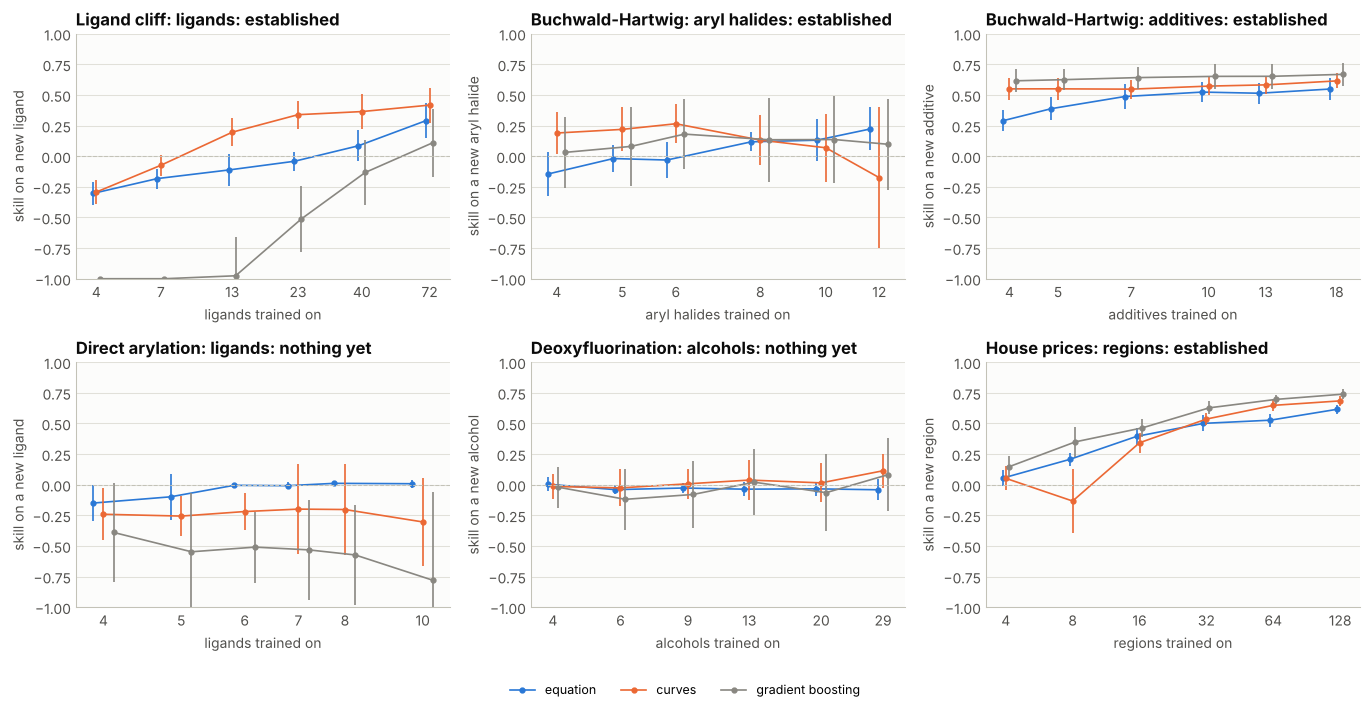

In [13]:
items = []
for name, T in TABLES.items():
    for unit, groups in T["units"].items():
        t0 = time.time()
        L = learning_curve(T["X"], T["y"], NewGroups(groups, f"new {unit}"), family=T["family"],
                           models={"gradient boosting": boosting(T["family"])},
                           n_repeats=1 if FAST else None, n_jobs=N_JOBS)  # fmt: skip
        key = f"{name}: {unit}s"
        CURVES[key] = L
        items.append((key, L))
        print(f"\n{key} ({time.time() - t0:.0f} s)")
        print(L)
plot_curves(items)
save("curves", {k: L.to_dict() for k, L in CURVES.items()})

## 3. Forecast first, then reveal

Can a curve like these say what more molecules would give? The test: draw 13 (or 20, or 30) of
the 90 phosphines and treat them as all there is. Measure the curve on them, and write down
(a) its state, (b) the skill at its largest size, and (c) what the textbook extension of a
learning curve, a power law fitted to the measured sizes, says for 1.5, 2 and 3 times as many
ligands. Then really use that many ligands (the ones in hand plus others) and measure the skill
on ligands that neither the curve nor the extension has seen.

The same is done on the 37 alcohols, on the 160 housing regions, where skill is established
early, and on two made-up populations of 300 groups with known structure: one in which two group properties act
linearly (skill grows smoothly with more groups) and one in which the target is high only inside
a window of one property (nothing can be found until both sides of the window are populated).

Ligand cliff, 13 ligands in hand: 36 checks (911 s)
Ligand cliff, 20 ligands in hand: 36 checks (860 s)
Ligand cliff, 30 ligands in hand: 24 checks (808 s)
Deoxyfluorination, 12 alcohols in hand: 24 checks (53 s)
Deoxyfluorination, 18 alcohols in hand: 12 checks (39 s)
House prices, 12 regions in hand: 16 checks (295 s)
House prices, 24 regions in hand: 16 checks (254 s)
House prices, 48 regions in hand: 16 checks (274 s)
Made up: smooth, 12 groups in hand: 24 checks (43 s)
Made up: smooth, 24 groups in hand: 24 checks (46 s)
Made up: window, 12 groups in hand: 24 checks (72 s)
Made up: window, 24 groups in hand: 24 checks (84 s)
1. Extending the fitted curve, against what was then measured (mean error and mean absolute error)


checks  extended  realized  error  abs_error
data              state                                                    
Deoxyfluorination nothing yet      36     -0.02      0.05  -0.07       0.10
House prices      established      34      0.62      0.60   0.02       0.12
                  nothing yet      14      0.20      0.52  -0.32       0.38
Ligand cliff      established      14      0.42      0.40   0.02       0.10
                  nothing yet      82      0.03      0.21  -0.18       0.22
Made up: smooth   established      40      0.63      0.69  -0.06       0.13
                  nothing yet       8      0.09      0.67  -0.59       0.59
Made up: window   established      26      0.38      0.55  -0.16       0.22
                  nothing yet      22      0.16      0.50  -0.34       0.36

2. Established skill: was it kept when units were added (realized at or above the floor)?


,checks,kept,floor,held,realized
data,,,,,
House prices,34,0.91,0.39,0.53,0.60
Ligand cliff,14,1.00,0.12,0.33,0.40
Made up: smooth,40,0.98,0.33,0.53,0.69
Made up: window,26,1.00,0.14,0.35,0.55


   all tables: kept in 96% of 114 checks
3. Established skill: how much more did more units give (realized minus held)?


,checks,gain,gained_over_0_05
data,,,
House prices,34,0.07,0.50
Ligand cliff,14,0.07,0.57
Made up: smooth,40,0.16,0.78
Made up: window,26,0.19,0.88


4. 'Nothing yet': how often was there skill after all, with two or three times the units?


checks  held  realized  skill_later
data              rung                                         
Deoxyfluorination curves         6 -0.08      0.12         0.83
                  equation       6 -0.07      0.01         0.00
House prices      curves         8 -0.11      0.63         1.00
                  equation       6  0.29      0.47         1.00
Ligand cliff      curves        22  0.04      0.38         1.00
                  equation      30 -0.11      0.12         0.60
Made up: smooth   equation       8  0.08      0.68         1.00
Made up: window   curves        14  0.11      0.47         1.00
                  equation       8  0.07      0.60         1.00

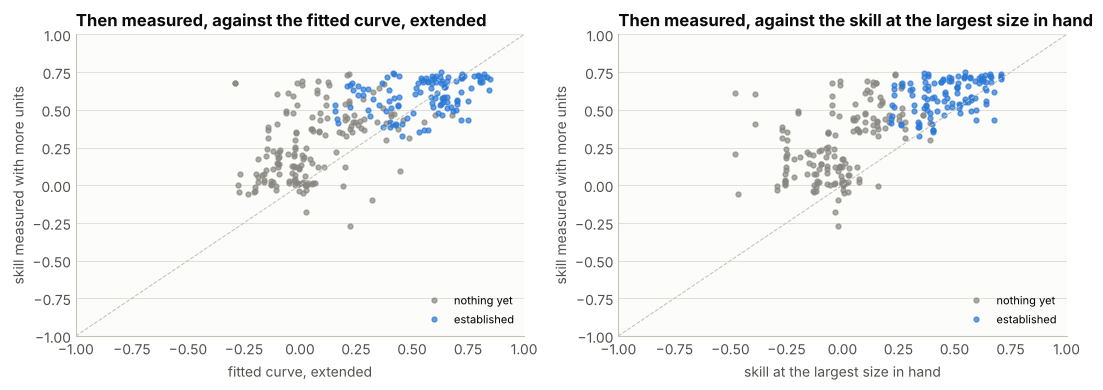

In [14]:
def population(kind, n_groups=300, per=8, seed=7):
    # a made-up population of groups with a known kind of group-level signal
    rng = np.random.default_rng(seed)
    g = np.repeat(np.arange(n_groups), per)
    Z = rng.normal(size=(n_groups, 4))
    if kind == "smooth":  # two group properties act linearly
        f = 1.2 * Z[:, 0] + 0.6 * Z[:, 1]
    else:  # high only inside a window of one property
        f = 2.4 * ((Z[:, 0] > -0.4) & (Z[:, 0] < 0.9))
    x = rng.normal(size=len(g))
    y = x + (f + 0.8 * rng.normal(size=n_groups))[g] + 0.5 * rng.normal(size=len(g))
    X = pd.DataFrame(np.column_stack([x, Z[g]]), columns=["x", "z1", "z2", "z3", "z4"])
    return {"X": X, "y": y, "family": "gaussian", "units": {"group": g}}


PLANS = [  # table, unit, units in hand, multiples, trials
    ("Ligand cliff", "ligand", (13, 20, 30), (1.5, 2.0, 3.0), 6),
    ("Deoxyfluorination", "alcohol", (12, 18), (1.5, 2.0), 6),
    ("House prices", "region", (12, 24, 48), (2.0, 3.0), 4),
    ("Made up: smooth", "group", (12, 24), (2.0, 3.0), 6),
    ("Made up: window", "group", (12, 24), (2.0, 3.0), 6),
]
TABLES["Made up: smooth"], TABLES["Made up: window"] = population("smooth"), population("window")
frames = []
for name, unit, haves, factors, trials in PLANS:
    T = TABLES[name]
    for have in haves:
        t0 = time.time()
        b = backtest(T["X"], T["y"], NewGroups(T["units"][unit], f"new {unit}"), have=have,
                     factors=factors, n_trials=2 if FAST else trials, n_acquisitions=2 if FAST else 6,
                     family=T["family"], n_sizes=5, n_repeats=1 if FAST else None, n_jobs=N_JOBS)  # fmt: skip
        frames.append(b.assign(data=name))
        print(f"{name}, {have} {unit}s in hand: {len(b)} checks ({time.time() - t0:.0f} s)")
B = pd.concat(frames, ignore_index=True)
B["rung"] = B.rung.str.split(",").str[0]
B = B[B.realized > -1.5]  # a handful of checks are wrecked by one small test set
B["extension error"] = B.extended - B.realized
B["kept"] = B.realized >= B.lo
B["gain"] = B.realized - B.held
BACKTESTS["all"] = B

print(
    "1. Extending the fitted curve, against what was then measured (mean error and mean absolute error)"
)
display(B.groupby(["data", "state"]).agg(checks=("gain", "size"), extended=("extended", "mean"),
                                         realized=("realized", "mean"), error=("extension error", "mean"),
                                         abs_error=("extension error", lambda e: e.abs().mean())).round(2))  # fmt: skip
est = B[B.state != "nothing yet"]
print("2. Established skill: was it kept when units were added (realized at or above the floor)?")
display(est.groupby("data").agg(checks=("kept", "size"), kept=("kept", "mean"), floor=("lo", "mean"),
                                held=("held", "mean"), realized=("realized", "mean")).round(2))  # fmt: skip
print(f"   all tables: kept in {est.kept.mean():.0%} of {len(est)} checks")
print("3. Established skill: how much more did more units give (realized minus held)?")
display(est.groupby("data").agg(checks=("gain", "size"), gain=("gain", "mean"),
                                gained_over_0_05=("gain", lambda g: (g > 0.05).mean())).round(2))  # fmt: skip
ny = B[(B.state == "nothing yet") & (B.factor >= 2)]
print("4. 'Nothing yet': how often was there skill after all, with two or three times the units?")
display(ny.groupby(["data", "rung"]).agg(checks=("gain", "size"), held=("held", "mean"),
                                         realized=("realized", "median"),
                                         skill_later=("realized", lambda r: (r > 0.1).mean())).round(2))  # fmt: skip

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (col, label) in zip(
    axes, [("extended", "fitted curve, extended"), ("held", "skill at the largest size in hand")]
):
    style_axes(ax)
    for k, state in enumerate(["nothing yet", "established"]):
        s = B[B.state == state]
        ax.plot(s[col].clip(-1, 1), s.realized.clip(-1, 1), "o", color=[MUTED, SERIES[0]][k],
                markersize=3.5, alpha=0.7, label=state)  # fmt: skip
    ax.plot([-1, 1], [-1, 1], color=BASELINE, linewidth=PX, linestyle="--")
    ax.set_xlim(-1, 1)
    ax.set_ylim(-1, 1)
    finish_axes(ax, f"Then measured, against the {label}", label, "skill measured with more units")
    ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()
save("backtest", B.to_dict("records"))

## 4. What the molecules in hand could have shown

Where the state is "nothing yet", two readings are open: the description of a molecule holds
nothing, or it holds something that this many molecules cannot establish. The curve cannot tell
them apart, so the question is put to an experiment on the table itself.

A property is made up for each molecule: the molecule's own mean of the target, blurred so that
it captures a chosen share (20 to 90 %) of the molecule-to-molecule variance. It is added to the
table as one more descriptor and the whole analysis is run as on the real table. Detection means
the planted property enters the equation chosen for the shift. Two shapes: a **trend** (the
target rises with the property) and a **peak** (high in the middle, low on both sides: the shape
of a window, which needs both sides populated). The target itself is never simulated.

- The **floor** is the smallest share that is found in 80 % of plantings with the molecules in
  hand, read off the measured rates. "Nothing transfers" then reads: "no descriptor in this
  table captures that much".
- The **molecules needed** for a weaker property come from a law fitted to the counts. A property
  that captures a share q is a correlation of sqrt(q) over the molecules, and the evidence for
  a correlation over m molecules grows as sqrt((m - 2) q / (1 - q)); the detection rate is fitted
  as a probit curve in that quantity, up to three times the molecules in hand.

In [15]:
SETTINGS = {  # trials per cell; the Buchwald table has 3955 rows and takes longest
    "Ligand cliff: ligands": dict(n_trials=12),
    "Direct arylation: ligands": dict(n_trials=16),
    "Deoxyfluorination: alcohols": dict(n_trials=24),
    "Buchwald-Hartwig: aryl halides": dict(n_trials=8, sizes=[8, 15]),
    "Buchwald-Hartwig: additives": dict(n_trials=8, sizes=[11, 22]),
}
rows = []
for key, opts in SETTINGS.items():
    name, unit = key.split(": ")[0], key.split(": ")[1][:-1]
    T = TABLES[name]
    if FAST:
        opts = dict(n_trials=3, shares=(0.3, 0.9), sizes=opts.get("sizes"))
    t0 = time.time()
    D = detectable(T["X"], T["y"], NewGroups(T["units"][unit], f"new {unit}"), family=T["family"],
                   n_jobs=N_JOBS, **opts)  # fmt: skip
    FLOORS[key] = D
    print(f"\n=== {key} ({time.time() - t0:.0f} s)")
    print(D)
    row = {"component": key, "in hand": D.n_units, "state of the curve": CURVES[key].state()}
    for shape in ("trend", "peak"):
        row[f"floor, {shape}"] = floor_text(D, shape)
        for q in (0.3, 0.5):
            need = D.needed(q, shape)
            row[f"needed for {int(100 * q)} %, {shape}"] = (
                f"more than {int(3 * D.n_units)}" if need is None else need
            )
    rows.append(row)
floors = pd.DataFrame(rows).set_index("component")
display(floors)
save("floors", {k: D.to_dict() for k, D in FLOORS.items()})
save("floor_table", floors.reset_index().to_dict("records"))


=== Ligand cliff: ligands (737 s)
How often a planted property of each share was established (90 ligands in hand; 'established' means in 80 % of trials)
share        0.20  0.35  0.50  0.70  0.90
shape units                              
peak  45     0.17  0.58  0.67  1.00  1.00
      68     0.00  0.33  0.92  1.00  1.00
      90     0.08  0.92  0.92  1.00  1.00
trend 45     0.08  0.25  0.83  0.92  1.00
      68     0.08  0.33  1.00  1.00  1.00
      90     0.25  1.00  1.00  1.00  1.00

A property that captures nothing was admitted in 0% of trials (trend, 45 ligands), 0% of trials (trend, 68 ligands), 0% of trials (trend, 90 ligands), 0% of trials (peak, 45 ligands), 0% of trials (peak, 68 ligands), 0% of trials (peak, 90 ligands)

trend: with 90 ligands a property must capture at least 31% of the differences between ligands to be established
peak: with 90 ligands a property must capture at least 33% of the differences between ligands to be established

Ligands needed for a weaker prope

,in hand,state of the curve,"floor, trend","needed for 30 %, trend","needed for 50 %, trend","floor, peak","needed for 30 %, peak","needed for 50 %, peak"
component,,,,,,,,
Ligand cliff: ligands,90,established,31%,117,52,33%,129,57
Direct arylation: ligands,12,nothing yet,81%,more than 36,more than 36,none planted was enough,more than 36,more than 36
Deoxyfluorination: alcohols,37,nothing yet,44%,57,26,46%,80,36
Buchwald-Hartwig: aryl halides,15,established,59%,more than 45,22,84%,more than 45,more than 45
Buchwald-Hartwig: additives,22,established,64%,more than 66,46,64%,more than 66,more than 66


## 5. Checking the detection law the same way

The "molecules needed" in section 4 extend a fitted law beyond the molecules in hand, which is
the kind of step section 3 taught us to distrust. So it gets the same check, on the phosphines.

**Forecast, then reveal.** The law is fitted on 13 (or 20) ligands only. It then predicts how
often a planted property of each share would be found with 26, 40 and 60 ligands, and how many
ligands a property of 50 or 70 % needs. The rates are then measured by planting on that many of
the 90 ligands.

**The real descriptor.** The buried-volume window is a real property of real ligands. On all 90
ligands it captures a measurable share of the ligand-to-ligand variance. If the law is right,
the rate at which `pct_Vbur_min` is admitted from 13, 20, 30, ... ligands should follow the
law's curve for a peak of that share (the law fitted to the planted rates measured at 26, 40 and 60
ligands).

In [16]:
T = TABLES["Ligand cliff"]
Xl, yl, gl = T["X"], T["y"], T["units"]["ligand"]
labels = np.unique(gl)
shift = NewGroups(gl, "new ligand")
SHARES = (0.2, 0.35, 0.5, 0.7, 0.9)
rng = np.random.default_rng(0)

haves, reveal = (13, 20), [26, 40, 60]
t0 = time.time()
truth = detectable(Xl, yl, shift, family="binomial", sizes=reveal, shares=(0.5,) if FAST else SHARES,
                   n_trials=4 if FAST else 24, n_jobs=N_JOBS, random_state=99)  # fmt: skip
measured = truth.power.set_index(["shape", "units", "share"])["detected"]
print(f"measured detection rates with {reveal} ligands ({time.time() - t0:.0f} s)")
rows, needs = [], []
for have in haves:
    for trial in range(1 if FAST else 3):
        mine = rng.choice(labels, have, replace=False)
        sub = np.flatnonzero(np.isin(gl, mine))
        D = detectable(Xl.iloc[sub].reset_index(drop=True), yl[sub], NewGroups(gl[sub], "new ligand"),
                       family="binomial", shares=(0.3, 0.9) if FAST else SHARES,
                       n_trials=3 if FAST else 16, horizon=100.0, n_jobs=N_JOBS, random_state=trial)  # fmt: skip
        for shape, m, q in measured.index:
            rows.append({"in hand": have, "trial": trial, "shape": shape, "units": m, "share": q,
                         "predicted": float(D.rate(m, q, shape)), "measured": float(measured.loc[(shape, m, q)])})  # fmt: skip
        for shape in ("trend", "peak"):
            for q in (0.5, 0.7):
                needs.append(
                    {
                        "in hand": have,
                        "trial": trial,
                        "shape": shape,
                        "share": q,
                        "needed": D.needed(q, shape),
                    }
                )
check = pd.DataFrame(rows)
check["error"] = check.predicted - check.measured
print("Detection rate predicted from the ligands in hand, against the rate then measured")
display(check.groupby(["shape", "in hand", "units"]).agg(cells=("error", "size"), predicted=("predicted", "mean"),
                                                         measured=("measured", "mean"), error=("error", "mean"),
                                                         abs_error=("error", lambda e: e.abs().mean())).round(2))  # fmt: skip
print(
    f"all cells: mean error {check.error.mean():+.2f}, mean absolute error {check.error.abs().mean():.2f}"
)

# ligands needed: what the law fitted on the ligands in hand said, against the smallest size at
# which the planted property was then found in 80 % of plantings
needs = pd.DataFrame(needs)
crossing = []
for (shape, q), c in truth.power.groupby(["shape", "share"]):
    hit = c[c.detected >= 0.8].units
    crossing.append(
        {
            "shape": shape,
            "share": q,
            "measured": int(hit.min()) if len(hit) else f"more than {max(reveal)}",
        }
    )
crossing = pd.DataFrame(crossing).set_index(["shape", "share"])
said = needs.groupby(["shape", "share", "in hand"])["needed"].apply(
    lambda v: ", ".join("none" if pd.isna(x) else str(int(x)) for x in v)).unstack("in hand")  # fmt: skip
said.columns = [f"law from {c} ligands (each trial)" for c in said.columns]
display(
    said.join(
        crossing.rename(columns={"measured": "first size found in 80 % (of 26, 40, 60)"}),
        how="left",
    )
)

# the real descriptor: how much of the ligand-to-ligand variance does the fitted window capture,
# and how often is pct_Vbur_min admitted from m ligands?
full = PieceModel(family="binomial", select_on=shift).fit(Xl, yl)
piece = next(p for p in full.pieces_ if p.feature == "pct_Vbur_min")
_, idx = np.unique(gl, return_inverse=True)
means = np.bincount(idx, weights=yl) / np.bincount(idx)
first = np.array([np.flatnonzero(idx == k)[0] for k in range(len(labels))])
share = float(np.corrcoef(piece.unit(Xl["pct_Vbur_min"].to_numpy()[first]), means)[0, 1] ** 2)
print(f"\nOn all 90 ligands: {piece.text()}")
print(f"It captures {share:.2f} of the ligand-to-ligand variance of the share of active reactions.")


def admitted(keep):
    sub = np.flatnonzero(np.isin(gl, keep))
    m = PieceModel(family="binomial", select_on=NewGroups(gl[sub], "new ligand")).fit(
        Xl.iloc[sub].reset_index(drop=True), yl[sub])  # fmt: skip
    return "pct_Vbur_min" in m.variables_


real = []
for m in (13, 20, 30, 45, 60):
    hits = Parallel(n_jobs=N_JOBS)(delayed(admitted)(rng.choice(labels, m, replace=False))
                                   for _ in range(4 if FAST else 32))  # fmt: skip
    real.append({"ligands": m, "pct_Vbur_min admitted": float(np.mean(hits)),
                 "law: a peak of that share": float(truth.rate(m, share, "peak")),
                 "law: a trend of that share": float(truth.rate(m, share, "trend"))})  # fmt: skip
real = pd.DataFrame(real).set_index("ligands")
display(real.round(2))
save("law_check", check.to_dict("records"))
save("law_needed", said.join(crossing, how="left").reset_index().to_dict("records"))
save(
    "law_real",
    {"share": share, "piece": piece.text(), "rows": real.reset_index().to_dict("records")},
)

measured detection rates with [26, 40, 60] ligands (1283 s)
Detection rate predicted from the ligands in hand, against the rate then measured


cells  predicted  measured  error  abs_error
shape in hand units                                              
peak  13      26        15       0.18      0.48  -0.30       0.30
              40        15       0.25      0.60  -0.35       0.36
              60        15       0.33      0.72  -0.39       0.39
      20      26        15       0.38      0.48  -0.09       0.13
              40        15       0.47      0.60  -0.13       0.17
              60        15       0.56      0.72  -0.15       0.16
trend 13      26        15       0.38      0.58  -0.21       0.21
              40        15       0.46      0.66  -0.20       0.21
              60        15       0.55      0.79  -0.24       0.24
      20      26        15       0.55      0.58  -0.04       0.07
              40        15       0.65      0.66  -0.00       0.07
              60        15       0.75      0.79  -0.04       0.06

all cells: mean error -0.18, mean absolute error 0.20


law from 13 ligands (each trial) law from 20 ligands (each trial) first size found in 80 % (of 26, 40, 60)
shape share                                                                                                           
peak  0.5                      381, 400, 165                     88, 122, 136                                       60
      0.7                       165, 173, 72                       39, 54, 60                                       26
trend 0.5                       110, 224, 92                       46, 70, 41                                       60
      0.7                         49, 97, 41                       21, 31, 19                                       26


On all 90 ligands: W(pct_Vbur_min; 25.1, 31.4, 1.58)   [1 inside 25.1 to 31.4]
It captures 0.33 of the ligand-to-ligand variance of the share of active reactions.


,pct_Vbur_min admitted,law: a peak of that share,law: a trend of that share
ligands,,,
13,0.00,0.08,0.11
20,0.16,0.13,0.19
30,0.28,0.20,0.30
45,0.72,0.32,0.46
60,0.91,0.43,0.61


## 6. Which molecules: spread out, or at random?

If more molecules are to be made or bought, should they be chosen to cover the descriptor space?
For each draw some molecules are held out; from the rest, a training set of a given size is
chosen either at random or by farthest-point selection in the standardized space of the
molecule-level descriptors (start anywhere, then always take the molecule farthest from those
already chosen). Both are scored on the same held-out molecules.

In [17]:
def unit_table(X, g):
    # one row per unit: the standardized variables that are constant within every unit
    t = X.groupby(g).agg(["mean", "std"])
    keep = [
        c for c in X.columns if (t[(c, "std")].fillna(0) < 1e-9).all() and t[(c, "mean")].std() > 0
    ]
    Z = t[[(c, "mean") for c in keep]].to_numpy()
    return t.index.to_numpy(), (Z - Z.mean(axis=0)) / Z.std(axis=0)


def farthest(Z, pool, m, rng):
    chosen = [int(rng.choice(pool))]
    d = np.linalg.norm(Z[pool] - Z[chosen[0]], axis=1)
    while len(chosen) < m:
        k = int(np.argmax(d))
        chosen.append(int(pool[k]))
        d = np.minimum(d, np.linalg.norm(Z[pool] - Z[pool[k]], axis=1))
    return np.array(chosen)


def skill_of(T, unit, train, test):
    g = T["units"][unit]
    tr, te = np.flatnonzero(np.isin(g, train)), np.flatnonzero(np.isin(g, test))
    X, y = T["X"], T["y"]
    if np.ptp(y[tr]) == 0:
        return 0.0, 0.0
    m = PieceModel(family=T["family"], select_on=NewGroups(g[tr], f"new {unit}")).fit(
        X.iloc[tr].reset_index(drop=True), y[tr])  # fmt: skip
    fam = m.family
    p0 = np.full(len(te), y[tr].mean())

    def loss(p):
        if fam == "binomial":
            p = np.clip(p, 1e-3, 1 - 1e-3)
            return float(-(y[te] * np.log(p) + (1 - y[te]) * np.log(1 - p)).sum())
        return float(((y[te] - p) ** 2).sum())

    curves = m.source_.predict(m.design_.transform(X.iloc[te]))
    return 1 - loss(m.predict(X.iloc[te])) / loss(p0), 1 - loss(np.asarray(curves, float)) / loss(
        p0
    )


rows = []
for name, unit, sizes in [
    ("Ligand cliff", "ligand", (13, 20, 30)),
    ("Deoxyfluorination", "alcohol", (12, 20)),
]:
    T = TABLES[name]
    labels, Z = unit_table(T["X"], T["units"][unit])
    rng = np.random.default_rng(0)
    jobs = []
    for draw in range(4 if FAST else 24):
        perm = rng.permutation(len(labels))
        test, pool = perm[: len(labels) // 4], perm[len(labels) // 4 :]
        for m in sizes:
            jobs.append(
                (m, draw, "at random", labels[rng.choice(pool, m, replace=False)], labels[test])
            )
            jobs.append((m, draw, "spread out", labels[farthest(Z, pool, m, rng)], labels[test]))
    res = Parallel(n_jobs=N_JOBS)(delayed(skill_of)(T, unit, tr, te) for _, _, _, tr, te in jobs)
    for (m, draw, how, _, _), (eq, cu) in zip(jobs, res):
        rows.append(
            {"data": name, "units": m, "draw": draw, "chosen": how, "equation": eq, "curves": cu}
        )
S = pd.DataFrame(rows)
wide = S.pivot_table(
    index=["data", "units", "draw"], columns="chosen", values=["equation", "curves"]
)
out = []
for (name, m), w in wide.groupby(level=["data", "units"]):
    for rung in ("equation", "curves"):
        d = w[(rung, "spread out")] - w[(rung, "at random")]
        out.append({"data": name, "units": m, "rung": rung,
                    "at random (median skill)": w[(rung, "at random")].median(),
                    "spread out (median skill)": w[(rung, "spread out")].median(),
                    "spread better in": f"{(d > 0).mean():.0%} of draws",
                    "median difference": d.median()})  # fmt: skip
spread = pd.DataFrame(out).set_index(["data", "units", "rung"])
display(spread.round(2))
save("spread", spread.reset_index().to_dict("records"))

at random (median skill)  spread out (median skill) spread better in  median difference
data              units rung                                                                                             
Deoxyfluorination 12    equation                      0.00                       0.00     54% of draws               0.00
                        curves                        0.06                       0.13     62% of draws               0.10
                  20    equation                     -0.00                       0.00     50% of draws               0.00
                        curves                        0.08                       0.09     50% of draws               0.00
Ligand cliff      13    equation                      0.00                       0.00     54% of draws               0.00
                        curves                        0.25                       0.03     21% of draws              -0.18
                  20    equation                      0.00                       0.00     62% of draws               0.00
                        curves                        0.35                       0.25     38% of draws              -0.08
                  30    equation                     -0.00                       0.00     58% of draws               0.00
                        curves                        0.41                       0.31     21% of draws              -0.07

## 7. The plan, per component

In [18]:
rows = []
for key, L in CURVES.items():
    t = L.top()
    row = {"component": key, "in hand": L.n_units, "best rung": L.best.split(",")[0], "state": L.state(),
           "skill at the largest size": f"{t.skill:.2f} [{t.lo:.2f}, {t.hi:.2f}]",
           "expected to be kept": "" if L.floor() is None else f"{L.floor():.2f}"}  # fmt: skip
    D = FLOORS.get(key)
    if D is not None:
        for shape in ("trend", "peak"):
            row[f"a {shape} must capture"] = floor_text(D, shape)
    rows.append(row)
plan = pd.DataFrame(rows).set_index("component").fillna("")
display(plan)
for key, L in CURVES.items():
    print(f"{key}. {L.advice()}")
save("plan", plan.reset_index().to_dict("records"))

,in hand,best rung,state,skill at the largest size,expected to be kept,a trend must capture,a peak must capture
component,,,,,,,
Ligand cliff: ligands,90,curves,established,"0.42 [0.27, 0.56]",0.27,31%,33%
Buchwald-Hartwig: aryl halides,15,equation,established,"0.22 [0.05, 0.40]",0.05,59%,84%
Buchwald-Hartwig: additives,22,gradient boosting,established,"0.67 [0.57, 0.76]",0.57,64%,64%
Direct arylation: ligands,12,equation,nothing yet,"0.01 [-0.03, 0.04]",,81%,none planted was enough
Deoxyfluorination: alcohols,37,curves,nothing yet,"0.11 [-0.02, 0.25]",,44%,46%
House prices: regions,160,gradient boosting,established,"0.74 [0.70, 0.78]",0.70,,


Ligand cliff: ligands. Established: skill on a new ligand is 0.42 with 72 ligands, and at least 0.27 is expected to be kept with more. Whether more ligands add to it the curve does not say.
Buchwald-Hartwig: aryl halides. Established: skill on a new aryl halide is 0.22 with 12 aryl halides, and at least 0.05 is expected to be kept with more. Whether more aryl halides add to it the curve does not say.
Buchwald-Hartwig: additives. Established: skill on a new additive is 0.67 with 18 additives, and at least 0.57 is expected to be kept with more. Whether more additives add to it the curve does not say.
Direct arylation: ligands. Nothing yet: no skill on a new ligand is established with 12 ligands. A curve at zero does not say where it would leave zero; detectable() says what these ligands could have shown and how many a weaker property needs.
Deoxyfluorination: alcohols. Nothing yet: no skill on a new alcohol is established with 37 alcohols. A curve at zero does not say where it would leav

### Reading

Skill is the share of the baseline's loss removed on reactions of molecules held out; intervals are 95 %, over the held-out molecules. A curve scores the whole model on reactions of an unseen molecule while the other components are still seen, so "established" for a component is not the same as "its descriptors transfer" (that is the ledger's verdict per block).

This notebook was run again with `transferledger` 0.2, which repairs the fit for yes/no targets (`KAN_Prospective_Followup` has the story). Only the phosphine table, the one yes/no target, changed; the last section lists what the first run said and no longer holds.

**Do the molecules differ at all?** In every component, yes.

| Component | Molecules | Knowing which molecule it is adds | Its description reaches |
|---|---|---|---|
| Direct arylation: ligands | 12 | +0.90 [0.74, 1.07] | 101 % |
| Deoxyfluorination: alcohols | 37 | +0.88 [0.82, 0.94] | 101 % |
| Buchwald-Hartwig: aryl halides | 15 | +0.70 [0.46, 0.94] | 101 % |
| Ligand cliff: ligands | 90 | +0.46 [0.35, 0.58] | 104 % |
| Buchwald-Hartwig: additives | 22 | +0.32 [0.20, 0.44] | 101 % |
| House prices: regions | 160 | +0.06 [0.05, 0.08] | no description in the table |

- On reactions of molecules already seen, the identity of the molecule is worth 0.3 to 0.9 of skill in the chemistry tables. There is something to explain, so a "does not transfer" in these tables is about the descriptors or the number of molecules, not about a table with nothing in it. (The Ni reactions of the outside table in `KAN_Prospective_Followup` are the other case: +0.001.)
- The description reaches all of it. That is close to automatic and is not evidence that the descriptors are right: flexible curves in several descriptors can tell apart every molecule they have seen. Whether they carry to a new one is what the ledger and the curves below measure.

**Where each component stands.**

| Component | Molecules in hand | Skill on a new molecule, at the largest size | State | A trend must capture | A peak must capture |
|---|---|---|---|---|---|
| Ligand cliff: ligands | 90 | 0.42 [0.27, 0.56] | established | 31 % | 33 % |
| Buchwald-Hartwig: additives | 22 | 0.67 [0.57, 0.76] | established | 64 % | 64 % |
| Buchwald-Hartwig: aryl halides | 15 | 0.22 [0.05, 0.40] | established | 59 % | 84 % |
| Deoxyfluorination: alcohols | 37 | 0.11 [-0.02, 0.25] | nothing yet | 44 % | 46 % |
| Direct arylation: ligands | 12 | 0.01 [-0.03, 0.04] | nothing yet | 81 % | more than 90 % |
| House prices: regions | 160 | 0.74 [0.70, 0.78] | established | | |

The last two columns are the detection floor: the share of the differences between molecules that one property must capture to be found in 80 % of plantings.

- **For the phosphines the two rungs part ways.** The additive curves have skill on a new ligand from 13 ligands on (0.20 [0.08, 0.31]; 0.34 [0.23, 0.45] with 23). The equation chosen for a new ligand, the readable form, is not above zero until 72 (0.09 [-0.04, 0.21] with 40, 0.29 [0.15, 0.43] with 72). Predicting for a new ligand was possible early; naming what it rests on took most of the ligands.
- **For the additives the curve is flat from the start** (0.62 with 4 additives, 0.67 with 18). A reaction with a new additive is predicted from the other components; more additives would add little to that.
- **For a new aryl halide only the equation chosen for that shift is above zero.** The additive curves and gradient boosting are not (curves -0.18 [-0.75, 0.40] with 12).

**What a curve can say about more molecules (276 checks: measure on a part, then add molecules and measure again).**

| Statement | Result | Kept in the library |
|---|---|---|
| A curve at zero, extended | too low by 0.11, 0.23 and 0.30 at 1.5, 2 and 3 times the molecules (162 checks) | no |
| Holding the last value instead | too low by 0.16, 0.30 and 0.40 | no |
| Established skill is kept with more molecules | 110 of 114 checks | yes: `floor()` |
| How much more molecules add to established skill | 0.07 on housing and on the phosphines, 0.16 and 0.19 on the made-up populations; less than 0.05 in 31 % of checks | no number is given |

- Curves measured on 13 phosphines and extended to 39 said 0.18; 0.38 was then measured. Where nothing was established with 13 to 30 phosphines, the curves rung had skill above 0.1 in every one of the 22 checks at two or three times as many, and the equation in 60 % of 30.
- So a curve reports a state and a floor, and forecasts nothing. A curve at zero is silent, not negative.

**What the molecules in hand could have shown.**

- **Direct arylation, 12 ligands.** Only a trend that captures 81 % of the differences between ligands could have been established, and no peak at all (a peak capturing 90 % was found in 69 % of plantings). "The ligand block does not transfer" is therefore no evidence that ligand properties do not matter.
- **Deoxyfluorination, 37 alcohols.** A property capturing half of the differences between alcohols would have been found in 88 % (peak) to 100 % (trend) of plantings. None was found, so no descriptor in this table captures that much. Here the description of an alcohol is at least part of the limit.
- **Buchwald-Hartwig.** With 15 aryl halides and 22 additives the floors are 59 to 84 %. Anything weaker is out of reach of these tables.
- **Ligand cliff, 90 ligands.** The floor is 31 to 33 %. The buried-volume window captures 33 % of the differences between ligands: it sits at the floor, and it was found.
- A planted property that captures nothing was admitted in 4 of 376 trials.

**Is the law for "molecules needed" right?** Roughly, for a trend; for a peak it asks for too many; and it needs about 20 molecules.

| Law fitted on | Predicted detection rate at 26 to 60 ligands, trend | The same, peak |
|---|---|---|
| 13 ligands | too low by 0.20 to 0.24 | too low by 0.30 to 0.39 |
| 20 ligands | too low by 0.00 to 0.04 | too low by 0.09 to 0.15 |

- Ligands needed for a property found in 80 % of plantings, law fitted on 20 ligands against the first of 26, 40, 60 at which it was measured (50 and 70 %): for a trend 41 to 70 against 60 and 19 to 31 against 26; for a peak 88 to 136 against 60 and 39 to 60 against 26. Fitted on 13 ligands it gave 41 to 400.
- So for a trend the law was within 0.7 to 1.2 times what was enough, as far as three sizes can tell (a number between 40 and 60, or below 26, cannot be shown wrong). For a peak it asked for 1.5 to 2.3 times as many.
- The real descriptor was found sooner than a planted one of its share. `pct_Vbur_min` was admitted in 0, 16, 28, 72 and 91 % of draws of 13, 20, 30, 45 and 60 ligands; the law for a planted peak of 33 % says 8, 13, 20, 32 and 43 %. A possible reason, not tested: a planted property overlaps with descriptors already in the table, a real one is one of them.
- For the 12 arylation ligands and the 15 aryl halides the law is outside what was checked.

**Which molecules.** Choosing them to cover the descriptor space was not better than choosing at random. On the phosphines it was worse (curves rung, median skill 0.31 against 0.41 with 30 ligands; better in 21 % of 24 draws); on the alcohols there was no difference.

**The plan.**

| Component | Verdict in the ledger | What this adds | What would change it |
|---|---|---|---|
| Direct arylation: ligands | does not transfer | the ligands differ (+0.90); 12 could not have shown a property of the strength of the phosphine threshold | more ligands: 45 to 60 was enough for the phosphine threshold (72 and 91 % of draws); 24 would not be (16 to 28 %) |
| Deoxyfluorination: alcohols | does not transfer | the alcohols differ (+0.88); 37 would have shown a property capturing half; none exists in the table | a richer description of an alcohol first; for a property capturing 30 %, 57 to 80 alcohols by the law |
| Buchwald-Hartwig: aryl halides | does not transfer | only a property capturing 59 to 84 % could have been shown | more aryl halides; the law says 22 for a trend capturing half, from too few molecules to be trusted |
| Buchwald-Hartwig: additives | undetermined | predictions for a new additive hold already, from the other components | nothing needed for prediction; to learn what about an additive matters, 46 for a trend capturing half by the law |
| Ligand cliff: ligands | transfers | 90 ligands were enough for the window; nothing weaker than 31 % is visible | the window is the target; a weaker property needs 117 to 129 ligands by the law |

**What the first run said and no longer holds.** With the fit of version 0.1 the curves rung of the phosphine table was below zero up to 23 ligands (-0.00 [-0.21, 0.21]) and the reading was "the threshold became visible between 23 and 40 ligands; a study with 20 of these ligands would have reported that nothing transfers". That was the defect: on few ligands a yes/no fit is nearly separated, and the iteration alternated between two bad fits. With the repaired fit the curves are above zero at 13. Two things from that reading survive in a weaker form: the equation needs 72 ligands, and the window's own descriptor is admitted in 16 % of draws of 20 ligands. The backtest's example (13 phosphines extended to 39) read -0.17 against 0.33; it now reads 0.18 against 0.38. The other tables have numeric targets and did not change in any digit.

**What this does not show.**

- Every check here hides molecules of a finished table and reveals them. Predictions written in advance and scored on outside tables are in `KAN_Prospective_Test` and `KAN_Prospective_Followup`.
- The law was checked on one table here (the phosphines, a yes/no outcome) and on one outside table, where the ligands it asked for were enough in 8 of 15 comparisons. The Buchwald-Hartwig floors rest on 8 plantings per cell and are coarse.
- A planted property acts alone and is given as one clean column. A real property spread over several correlated descriptors, or acting only through an interaction, is harder to find than the floor suggests.
- A floor is about one table's molecules and rows. It says what could be established, not what is true of the chemistry.